# Экспорт cyrillic_PP-OCRv5_mobile_rec в ONNX и подключение к Manuscript OCR

## 0. Введение

Пример для **manuscript-ocr 0.1.13**. Возьмём готовый кириллический распознаватель
[cyrillic_PP-OCRv5_mobile_rec](https://huggingface.co/PaddlePaddle/cyrillic_PP-OCRv5_mobile_rec)
из [официального списка моделей PaddleOCR](https://www.paddleocr.ai/latest/en/version3.x/module_usage/text_recognition.html).

Мы скачаем исходные веса, конвертируем их в ONNX и создадим конфиг для специального класса
`PPOCRRec` из библиотеки Manuscript OCR.

## 1. Установка зависимостей

Устанавливаем Manuscript OCR, инструменты конвертации и клиент Hugging Face.

In [1]:
%pip install "manuscript-ocr==0.1.13" "paddlepaddle==3.3.1" "paddle2onnx==2.1.0" "onnx>=1.16,<1.18" "huggingface-hub>=0.20"

  Using cached paddlepaddle-3.3.1-cp311-cp311-macosx_11_0_arm64.whl.metadata (8.6 kB)
  Using cached paddle2onnx-2.1.0-cp311-cp311-macosx_12_0_universal2.whl.metadata (5.4 kB)
  Using cached onnx-1.17.0-cp311-cp311-macosx_12_0_universal2.whl.metadata (16 kB)
  Using cached opt_einsum-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached onnxoptimizer-0.3.13-cp311-cp311-macosx_10_15_universal2.whl.metadata (3.2 kB)
  Using cached polygraphy-0.53.6-py3-none-any.whl.metadata (5.8 kB)
Using cached paddlepaddle-3.3.1-cp311-cp311-macosx_11_0_arm64.whl (104.5 MB)
Using cached paddle2onnx-2.1.0-cp311-cp311-macosx_12_0_universal2.whl (2.8 MB)
Using cached onnxoptimizer-0.3.13-cp311-cp311-macosx_10_15_universal2.whl (1.0 MB)
Using cached opt_einsum-3.3.0-py3-none-any.whl (65 kB)
Using cached onnx-1.17.0-cp311-cp311-macosx_12_0_universal2.whl (16.6 MB)
Using cached polygraphy-0.53.6-py3-none-any.whl (485 kB)
  Attempting uninstall: onnx
    Found existing installation: onnx 1.20.0
    Uninstall

## 2. Настройки и загрузка исходной модели

Исходную модель скачиваем из официального репозитория PaddlePaddle.
Для конвертации нужны `inference.json` (граф) и `inference.pdiparams` (веса).
`config.json` содержит настройки обработки изображения и словарь символов.

In [2]:
from pathlib import Path
import json
import os
import subprocess
import sys
from urllib.request import urlretrieve

import onnx
import onnxruntime as ort
from PIL import Image
from IPython.display import display
from huggingface_hub import snapshot_download
from manuscript import Pipeline
from manuscript.detectors import YOLO
from manuscript.layouts import SimpleSorting
from manuscript.recognizers import PPOCRRec
from manuscript.utils import create_page_from_image, visualize_page

MODEL_REPO = "PaddlePaddle/cyrillic_PP-OCRv5_mobile_rec"
SOURCE_DIR = Path("models/source/cyrillic_PP-OCRv5_mobile_rec")
MODEL_DIR = Path("models/cyrillic_PP-OCRv5_mobile_rec")
PROJECT_DIR = next((path for path in (Path.cwd(), *Path.cwd().parents)
                    if (path / "pyproject.toml").is_file()), Path.cwd())
IMAGES_DIR = PROJECT_DIR / "example" / "images"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ort.set_default_logger_severity(3)

snapshot_download(
    repo_id=MODEL_REPO,
    local_dir=SOURCE_DIR,
    allow_patterns=["inference.json", "inference.pdiparams", "config.json"],
)

/Users/user/manuscript-ocr/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 3 files: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:10<00:00,  3.42s/it]


'/Users/user/manuscript-ocr/notebooks/v_0_1_13/models/source/cyrillic_PP-OCRv5_mobile_rec'

## 3. Экспорт ONNX и подготовка конфига

`paddle2onnx` конвертирует готовый граф; ONNX проверяем через `onnx.checker`.
Используем opset 17 без дополнительного упрощения.

Для Manuscript преобразуем родной конфиг методом `PPOCRRec.create_config()`.
В нём сохраняется алфавит, поэтому отдельный `charset.txt` этой модели не нужен.
Paddle-декодер добавляет пробел в конец словаря; сохраняем тот же порядок символов.

`recognition_levels=["line"]` означает: при инференсе выбирать из `Page` области типа `line`.
Это не запускает детекцию или сегментацию строк.

В репозитории также есть готовый скрипт экспорта:
[`scripts/export_ppocr_rec.py`](../../scripts/export_ppocr_rec.py).
Его можно использовать вместо ручных шагов этого раздела.

In [3]:
weights_path = MODEL_DIR / "cyrillic_PP-OCRv5_mobile_rec.onnx"
config_path = MODEL_DIR / "cyrillic_PP-OCRv5_mobile_rec.json"

# Запускаем конвертер в том же окружении Python, что и ядро ноутбука.
subprocess.run([
    sys.executable, "-c", "from paddle2onnx.command import main; main()",
    "--model_dir", str(SOURCE_DIR),
    "--model_filename", "inference.json",
    "--params_filename", "inference.pdiparams",
    "--save_file", str(weights_path),
    "--opset_version", "17",
    "--optimize_tool", "None",
], check=True)
onnx.checker.check_model(onnx.load(str(weights_path)))

native_config = json.loads((SOURCE_DIR / "config.json").read_text(encoding="utf-8"))
characters = native_config["PostProcess"]["character_dict"]
if " " not in characters:
    characters.append(" ")
# Переводим конфиг Paddle в формат PPOCRRec: предобработка, декодирование и алфавит.
PPOCRRec.create_config(
    native_config,                  # Исходные настройки и словарь модели Paddle.
    recognition_levels=["line"],   # При распознавании выбирать элементы Page типа line.
    output_path=config_path,        # Сохранить JSON рядом с ONNX для дальнейшей загрузки.
)
print("ONNX прошёл проверку; конфиг создан.")

/Users/user/manuscript-ocr/env/lib/python3.11/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


[Paddle2ONNX] Start parsing the Paddle model file...
[Paddle2ONNX] Use opset_version = 17 for ONNX export.
[Paddle2ONNX] PaddlePaddle model is exported as ONNX format now.
2026-10-13 20:33:07 [INFO]	ONNX model saved in models/cyrillic_PP-OCRv5_mobile_rec/cyrillic_PP-OCRv5_mobile_rec.onnx.
ONNX прошёл проверку; конфиг создан.


In [4]:
# Для локальной PPOCRRec обязательны ONNX-веса и соответствующий конфиг.
# В этом конфиге уже есть словарь символов и правила предобработки.
for name in sorted(os.listdir(MODEL_DIR)):
    description = "ONNX-веса" if name.endswith(".onnx") else "Конфиг с предобработкой и алфавитом"
    print(f"{name}: {os.path.getsize(MODEL_DIR / name) / (1024 ** 2):.2f} МБ — {description}")

recognizer = PPOCRRec(
    weights=str(MODEL_DIR / "cyrillic_PP-OCRv5_mobile_rec.onnx"),
    config=str(MODEL_DIR / "cyrillic_PP-OCRv5_mobile_rec.json"),
    device="cpu",
)

cyrillic_PP-OCRv5_mobile_rec.json: 0.01 МБ — Конфиг с предобработкой и алфавитом
cyrillic_PP-OCRv5_mobile_rec.onnx: 7.67 МБ — ONNX-веса


## 4. Распознавание отдельного кропа

На весь кроп создаём одну область `line`, поскольку такой уровень указан в конфиге распознавателя.

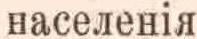

Текст: населенія
Confidence: 0.9468728767500983


In [5]:
crop_path = IMAGES_DIR / "crops" / "crop3.png"
full_path = IMAGES_DIR / "full" / "img5.jpeg"
IMAGE_SOURCE = "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images"
for relative, path in (("crops/crop3.png", crop_path), ("full/img5.jpeg", full_path)):
    if not path.is_file():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{IMAGE_SOURCE}/{path.name}", path)

display(Image.open(crop_path))
page = create_page_from_image(crop_path, region_type="line")
result = recognizer.predict(page, image=crop_path)
line = next(node for node in result.descendants if node.type == "line")
print("Текст:", result.get_text(format="plain"))
print("Confidence:", line.recognition_confidence)

## 5. YOLO и распознаватель в одном пайплайне

YOLO находит **слова**, а конфиг распознавателя выбирает **строки**.
Поэтому между ними используем `SimpleSorting`: он собирает слова в строки и упорядочивает их.

YOLO загружается по имени пресета из реестра Manuscript OCR. Распознаватель передаём как готовый
объект с локальными ONNX-весами. Корректор в этом примере отключён.

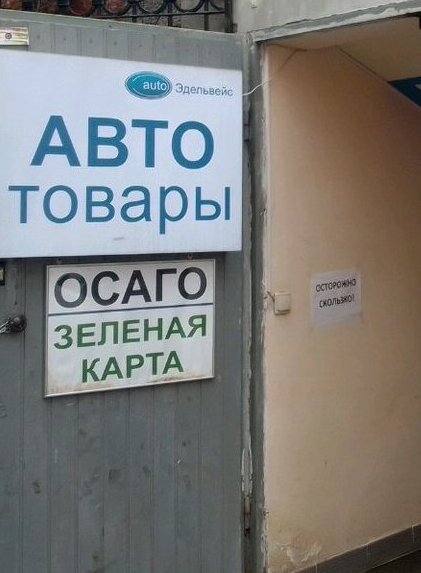

auto Эдельвейс
ABTO
товары
ОСАГО
3ЕЛЕНАЯ
KAPTA

ОСТОРОЖНО
СКОЛЬЗКО


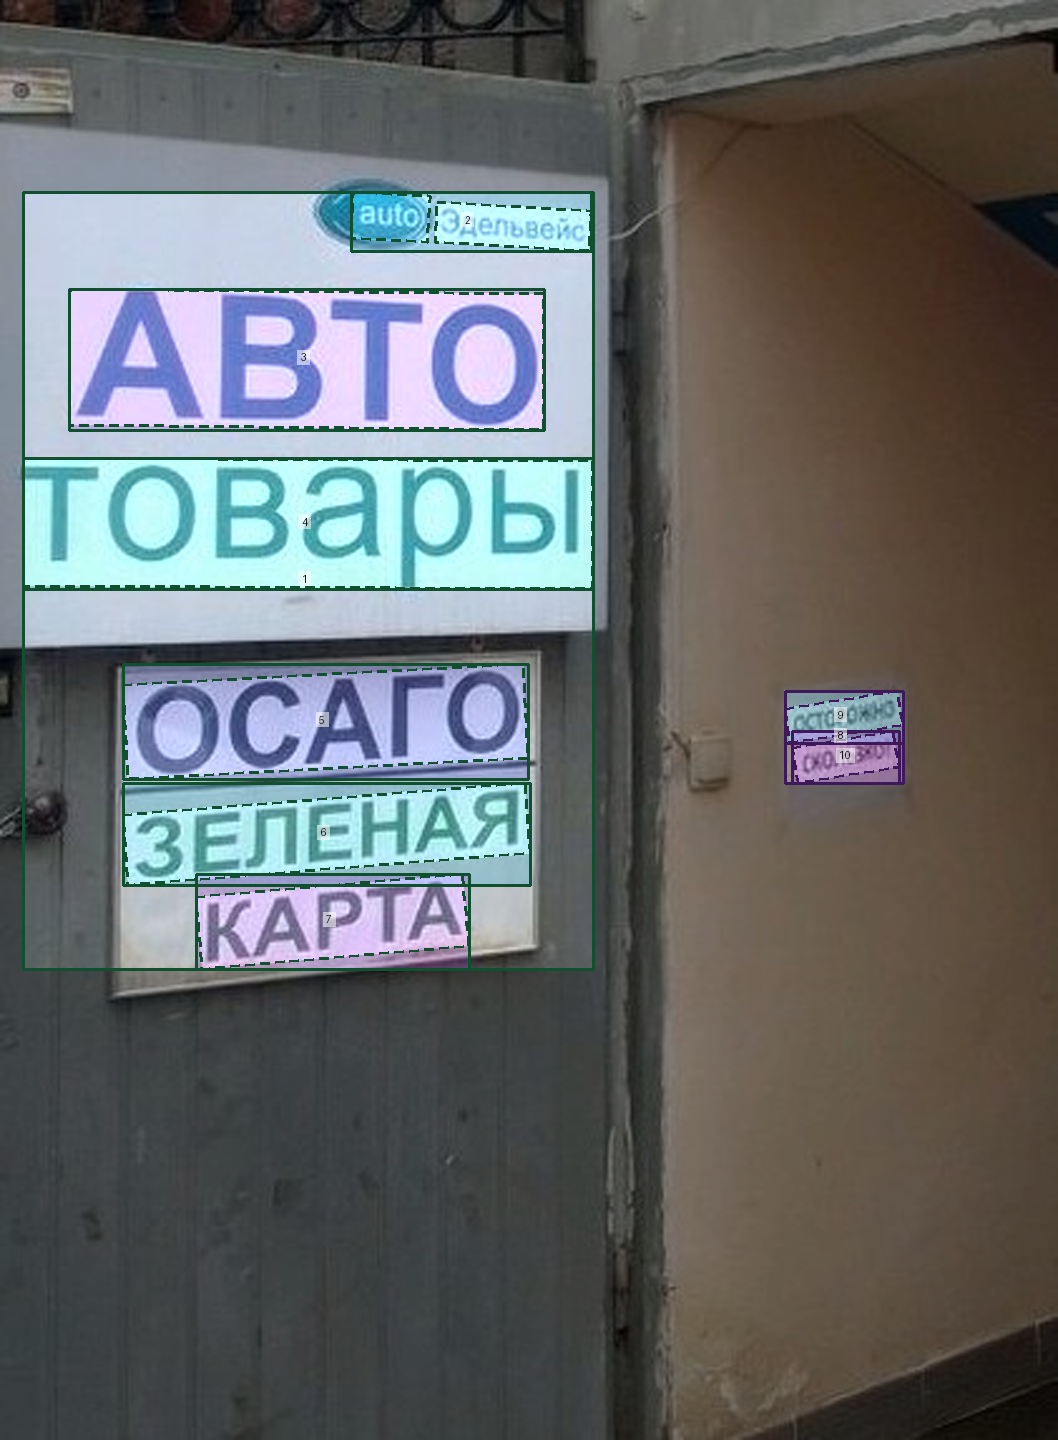

In [6]:
display(Image.open(full_path))

pipeline = Pipeline(
    detector=YOLO(weights="yolo26s_obb_text_g1", device="cpu"),
    layout=SimpleSorting(),
    recognizer=recognizer,  # Наш cyrillic_PP-OCRv5_mobile_rec, загруженный через PPOCRRec.
    corrector=None,
)
page = pipeline.predict(full_path)["page"]
print(page.get_text(format="plain"))
display(visualize_page(full_path, page, max_size=1440, upscale=True))